In [1]:
library( dplyr )
library( ggplot2 )

mytheme = function( fontsize = 16 ) {
	(
		theme_minimal( fontsize )
		+ theme(
			axis.title.y = element_text( angle = 0, hjust = 1, vjust = 0.5 )
		)
	)
}

ggplot2::set_theme( mytheme() )

simulate_two_dice <- function( n, probabilities = rep( 1/6, 6 ) ) {
	outcomes = 1:6
	(
		sample( outcomes, size = n, replace = T, prob = probabilities )
		+ sample( outcomes, size = n, replace = T, prob = probabilities )
	)
}

likelihood <- function( observed, probabilities = rep( 1/6, 6 ) ) {
	dice1 = tibble::tibble( dice1 = 1:6, dice1_probability = probabilities )
	dice2 = tibble::tibble( dice2 = 1:6, dice2_probability = probabilities )
	probabilities = (
		dice1
		%>% cross_join( dice2 )
		%>% mutate(
			sum_of_dice = dice1 + dice2,
			probability = dice1_probability * dice2_probability
		)
		%>% group_by( sum_of_dice )
		%>% summarise(
			number_of_ways = n(),
			probability = sum( probability )
		)
	)

	return(
		tibble::tibble( sum_of_dice = observed )
		%>% left_join( probabilities, by = "sum_of_dice" )
	)
}

total_loglikelihood = function( observed, probabilities = rep( 1/6, 6 ) ) {
	sum( log( likelihood( observed, probabilities = probabilities )$probability ))
}



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




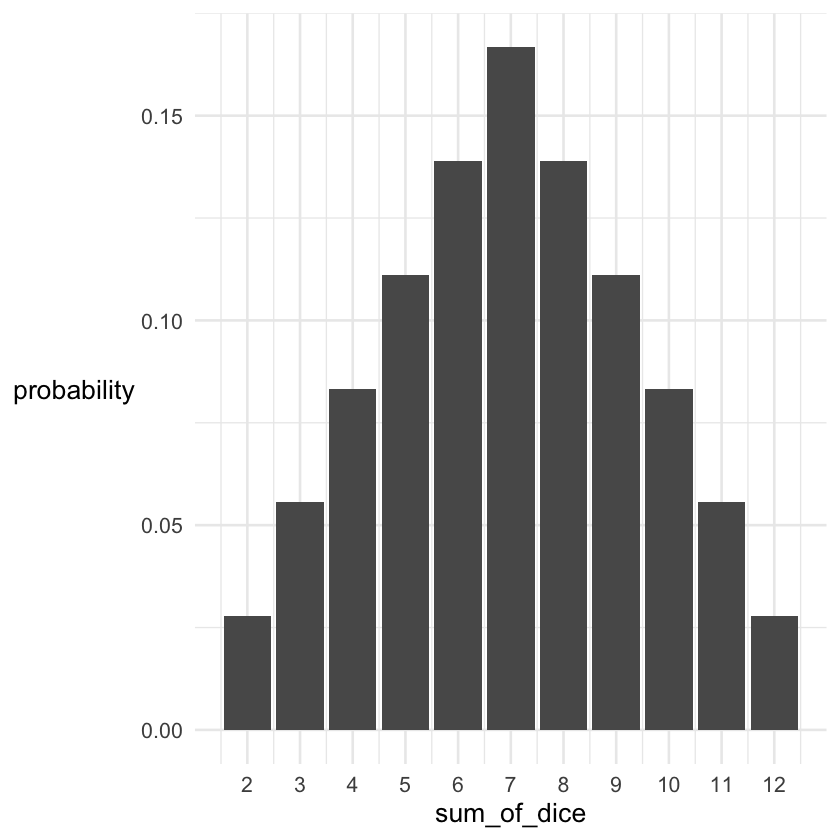

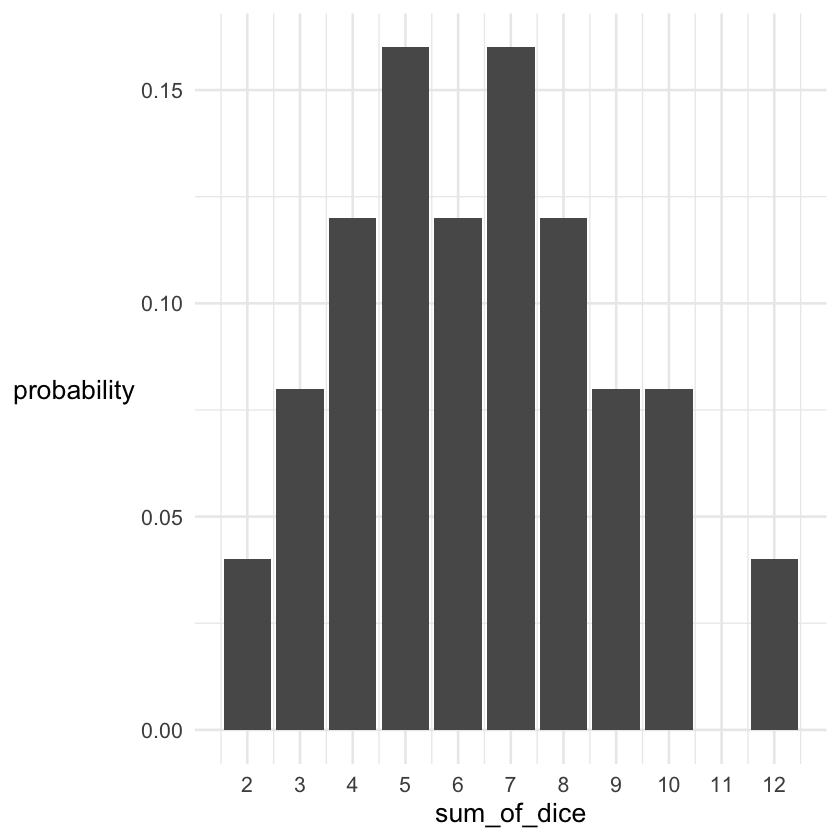

In [4]:
ggplot( data = likelihood( 2:12 ) ) + geom_col( aes( x = sum_of_dice, y = probability )) + scale_x_continuous( breaks = 2:12 )
ggplot( data = likelihood( 2:12, c( 0.2, 0.2, 0.2, 0.2, 0, 0.2 ) ) ) + geom_col( aes( x = sum_of_dice, y = probability )) + scale_x_continuous( breaks = 2:12 )


Rows: 30 Columns: 2
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
dbl (2): roll, sum_of_dice

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


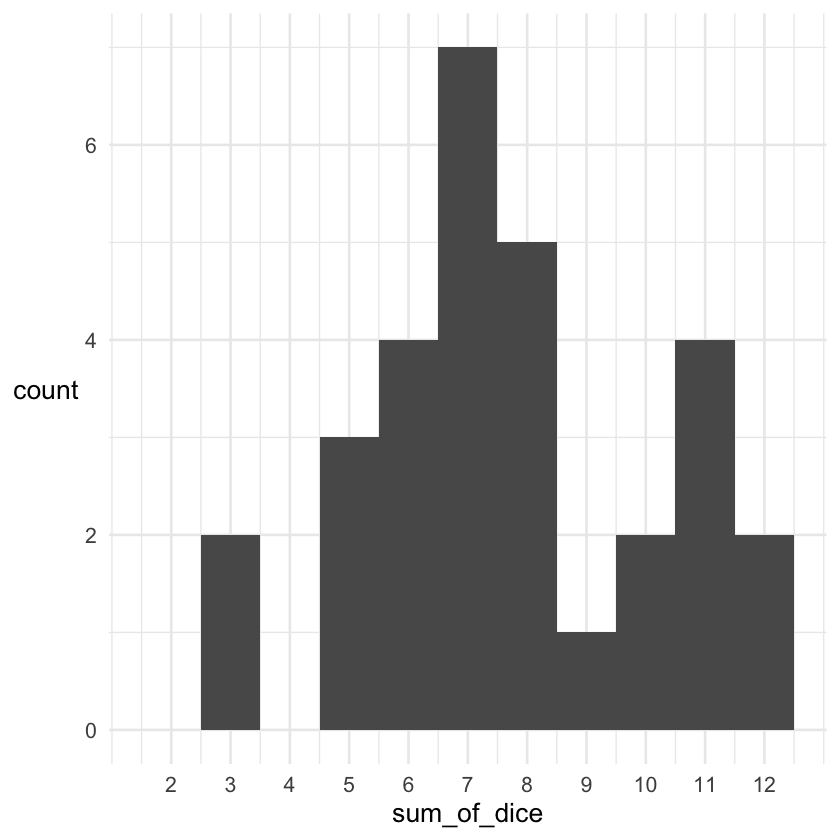

In [6]:
data = bind_rows(
	readr::read_tsv( "dice_data1.tsv" ),
#	readr::read_tsv( "dice_data2.tsv" ),
#	readr::read_tsv( "dice_data3.tsv" ),
)
ggplot( data = data ) + geom_histogram( aes( x = sum_of_dice ), breaks = 2:13 - 0.5 ) + scale_x_continuous( breaks = 2:12 )


# A tibble: 7 × 4
  model       loglikelihood likelihood posterior
  <chr>               <dbl>      <dbl>     <dbl>
1 Normal dice         -68.6   1.65e-30     0.117
2 Omit 1             -Inf     0            0    
3 Omit 2             -Inf     0            0    
4 Omit 3              -66.7   1.08e-29     0.769
5 Omit 4              -68.6   1.60e-30     0.114
6 Omit 5             -Inf     0            0    
7 Omit 6             -Inf     0            0    


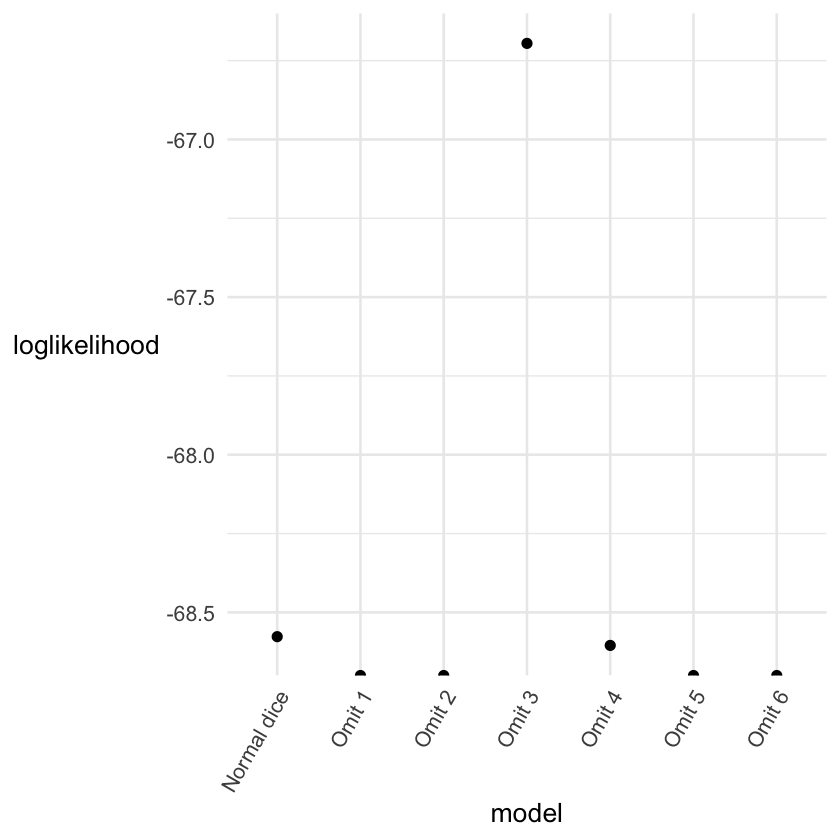

In [12]:
loglikelihoods = tibble::tribble(
	~model, ~loglikelihood,
	"Normal dice", total_loglikelihood( data$sum_of_dice, rep( 1/6, 6 ) ),
	"Omit 1", total_loglikelihood( data$sum_of_dice, c(  0.0,  0.2,  0.2,  0.2,  0.2,  0.2 ) ),
	"Omit 2", total_loglikelihood( data$sum_of_dice, c(  0.2,  0.0,  0.2,  0.2,  0.2,  0.2 ) ),
	"Omit 3", total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.0,  0.2,  0.2,  0.2 ) ),
	"Omit 4", total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.0,  0.2,  0.2 ) ),
	"Omit 5", total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.2,  0.0,  0.2 ) ),
	"Omit 6", total_loglikelihood( data$sum_of_dice, c(  0.2,  0.2,  0.2,  0.2,  0.2,  0.0 ) )
)

loglikelihoods$likelihood = exp(loglikelihoods$loglikelihood)
loglikelihoods$posterior = loglikelihoods$likelihood / sum( loglikelihoods$likelihood )

print( loglikelihoods )

(
	ggplot( data = loglikelihoods )
	+ geom_point( aes( x = model, y = loglikelihood ))
	+ mytheme()
    + theme( axis.text.x = element_text( angle = 60, hjust = 1, vjust = 1 ))
)



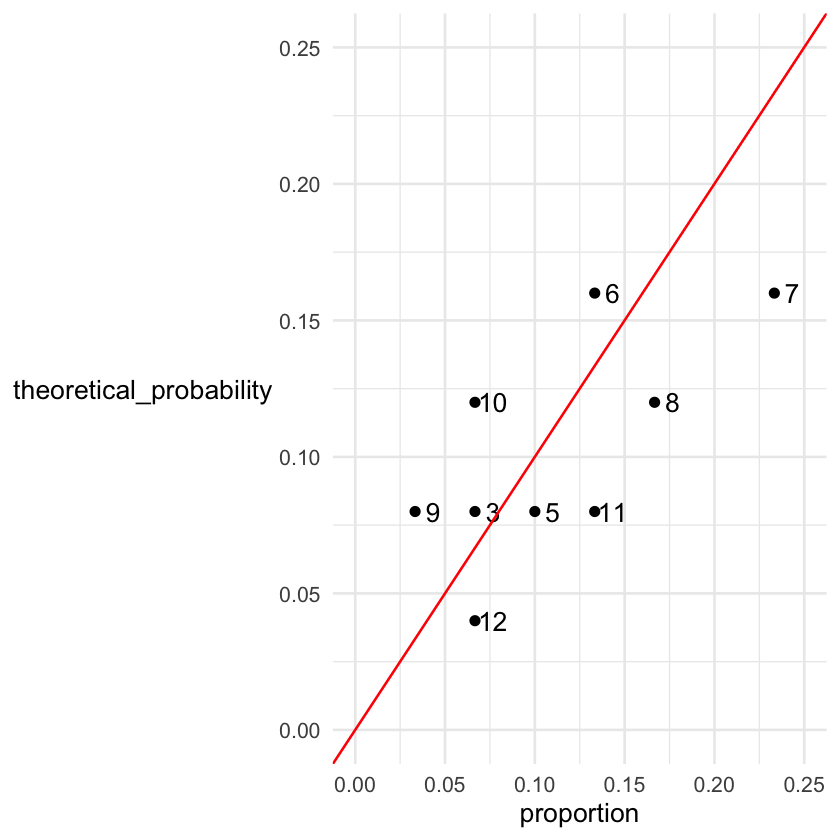

In [14]:
favourite_model = c(  0.2,  0.2,  0.0,  0.2,  0.2,  0.2 )

comparison = (
	data
	%>% group_by( sum_of_dice )
	%>% summarise( n = n(), proportion = n / nrow(data) )
	%>% mutate(
		theoretical_probability = likelihood( sum_of_dice, favourite_model )$probability
	)
)
(
	ggplot( data = comparison, mapping = aes( x = proportion, y = theoretical_probability ) )
	+ geom_point( )
	+ geom_text( aes( label = sum_of_dice, x = proportion + 0.01 ) )
	+ xlim( 0, 0.25 )
	+ ylim( 0, 0.25 )
	+ geom_abline( slope = 1, col = 'red' )
)
